# Gaming and Mental Health - Causal Inference Project

**By Faatimah Majothi**

## Introduction

Digital gaming has existed as far back as the 1970's and has seen a steep incline in the last decade coinciding with technological development. Concerns surrounding the impacts of digital gaming on health, both mental and physical, have existed for just as long, with a growing focus on the mental impacts in recent years. As digital gaming becomes more accessible and therefore widespread, the question of whether it directly causes or amplifies mental health issues is more crucial than ever.


In this project we will use the principles of a Causal Inference workflow to investigate the relationship between digital gaming and mental health. We aim to complete a clean data analysis project that showcases an understanding of causal inference analysis along with proficiency in the use of python libraries and machine learning models. 


As a reminder, a key point in any analysis of a relationship between two variables is that **correlation does not always indicate causation**.

**Project Scope:**
- A: Define the problem and variables:
  -	Create a detailed DAG (directional acyclical graph) using knowledge and assumptions about the data generating process (DGP).
  -	Identify the treatment, outcome, and confounders from the DAG.
- B: Import, explore and preprocess the data.
    - Check the available data against assumtions of casual inference.
- C: Estimate treatment effects (ATE, ATT) using the chosen machine learning model(s).
- D: Validate the model results and check refuters.
- Conclusion: Interpret and communicate the results.


### **Section A:** Causal DAG and Assumptions

In [14]:
# Setup
import os

# Import Libraries
import pandas as pd
import numpy as np

# Inference
import dowhy
from dowhy import CausalModel

# Machine Learning
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier 
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report,\
confusion_matrix, classification_report, ConfusionMatrixDisplay

# Set visualisation theme
from matplotlib import pyplot as plt
import seaborn as sns
plt.rcParams['figure.facecolor'] = '#F7F0DE'
plt.rcParams['axes.facecolor'] = '#FFFFFF'

# Data
import gdown
import zipfile

# Download zip file
url = 'https://drive.google.com/uc?export=download&id=1k43IO8kMviO0VFuVWAS9Km7ZATB6FEOi'
gdown.download(url, 'data.zip', quiet=False)

# Extract zip file
with zipfile.ZipFile('data.zip', 'r') as zip_ref:
    zip_ref.extractall('data_folder')

inf_data = pd.read_csv('data_folder/gaming_mental_health_10M_40features.csv')
inf_data.head(3)


Downloading...
From (original): https://drive.google.com/uc?id=1k43IO8kMviO0VFuVWAS9Km7ZATB6FEOi
From (redirected): https://drive.google.com/uc?id=1k43IO8kMviO0VFuVWAS9Km7ZATB6FEOi&confirm=t&uuid=78cf2153-446e-4132-a0aa-6ce2fb6a3319
To: c:\Users\bintm\Desktop\Projects\causal_inference\data.zip
100%|██████████| 67.4M/67.4M [00:03<00:00, 22.3MB/s]


,age,gender,income,daily_gaming_hours,weekly_sessions,years_gaming,sleep_hours,caffeine_intake,exercise_hours,stress_level,...,parental_supervision,loneliness_score,aggression_score,happiness_score,bmi,screen_time_total,eye_strain_score,back_pain_score,competitive_rank,internet_quality
0,51,Female,8615,3.68,22,17,5.26,1.00,0.18,3,...,0,2.87,3.19,5.20,19.69,4.71,5.71,4.81,80,10
1,41,Female,39453,5.70,34,16,9.20,0.70,1.44,8,...,7,4.17,7.73,5.40,26.37,6.62,6.77,3.99,57,2
2,27,Male,40466,1.58,8,22,7.39,2.24,3.15,3,...,9,9.38,2.85,5.17,25.15,9.30,2.16,4.75,59,10


**Identify variables:**


- X: Digital gaming habits
- Y: Mental health (stress/depression/etc.)
- Z: Confounders:
    - Income
    - Sleep
    - Caffiene/Drugs/Alcohol
    - Age
    - Activity
    - Health
    - Social activity
    - Work/Study

###### **There are many other possible confounders/variables that impact gaming habits and mental health, but these are some key points of interest.**

In [15]:
# Digraph syntax
causal_graph = """
digraph{
    age -> income;
    study_work -> gaming_hrs;
    study_work -> income;
    sleep -> m_health;
    m_health -> sleep_hrs;
    m_health -> socialising;
    study_work -> socialising;
    online_friends -> gaming_hrs;
    age -> restrictions;
    restrictions -> gaming_hrs;
    activity -> p_health;
    study_work -> activity;
    socialising -> gaming_hrs;
    p_health -> m_health;
    gaming_hrs -> m_health;
}
"""

# Variables DataFrame syntax
variables_df = pd.DataFrame(['age', 'income', 'study_work', 'gaming_hrs', 'sleep', 'm_health', 'sleep_hrs', 'socialising', 'online_friends', 'restrictions', 'activity', 'p_health']
)

The confounding variables we identified in the digraph code are present in the data available. Some of the columns in the data, such as `stress_level` and `depression_score` both fall under our `m_health` (overall mental health) variable. More confounding variables are likely present, but we have selected limited variables for `variables_df` to remain within the constraints of data usage for this project. This can be considered a **limitation** of the project. 

In [16]:
# DAG visualisation

dag_model = CausalModel(
    data=variables_df,
    graph=causal_graph,
    treatment='gaming',
    outcome='m_health'
)
dag_model.view_model()

If the above cell does not render the DAG diagram, the diagram below can be referenced instead:

![DAG diagram](mhealth_gaming_dag.jpeg)

In [17]:
# Identify the treatment, outcome, and confounders
print(inf_data.columns)

treat_var = 'm_health'
outcome = 'gaming_hrs'

Index(['age', 'gender', 'income', 'daily_gaming_hours', 'weekly_sessions',
       'years_gaming', 'sleep_hours', 'caffeine_intake', 'exercise_hours',
       'stress_level', 'anxiety_score', 'depression_score',
       'social_interaction_score', 'relationship_satisfaction',
       'academic_performance', 'work_productivity', 'addiction_level',
       'multiplayer_ratio', 'toxic_exposure', 'violent_games_ratio',
       'mobile_gaming_ratio', 'night_gaming_ratio', 'weekend_gaming_hours',
       'friends_gaming_count', 'online_friends', 'streaming_hours',
       'esports_interest', 'headset_usage', 'microtransactions_spending',
       'parental_supervision', 'loneliness_score', 'aggression_score',
       'happiness_score', 'bmi', 'screen_time_total', 'eye_strain_score',
       'back_pain_score', 'competitive_rank', 'internet_quality'],
      dtype='str')


From the columns in the inf_data DataFrame, the **treatment** variable `m_health` and the **outcome** variable `gaming_hrs` are not represented by single columns. Instead, several columns hold information about each row’s mental health and time spent gaming.

### **Section B:** EDA and Preprocessing

We now have the DAG as a starting point to our analysis of causality. However, the preview of available columns in the dataset highlighted that we do not yet have a clear treatment or outcome variable. To address this, we will begin familiarising with the contents of the dataset before deciding how to assign our existing data to our `gaming_hrs` **treatment** and `m_health` **outcome** variables.

##### **EDA:**

Before we can begin any kind of data wrangling, it is good practice to explore the raw dataset.
First, we will use visualisations and summary statistics to explore the available columns in the `inf_data` DataFrame for our EDA (Exploratory Data Analysis). Then, we will try to identify any issues and determine what changes need to be made in the preprocessing step.

In [18]:
# Preview data to be cleaned
print('DataFrame summary:')
inf_data.info()
print('\n')

for col in inf_data.columns:
    print('________________________________________________________________________________')
    print(f'{col} column information:\n')
    print(f'{col} data type: {inf_data[col].dtype}\n')
    print(f'{col} description: {inf_data[col].describe()}\n')
    if inf_data[col].nunique() <= 12:
        print(f'{col} values: {inf_data[col].unique()}\n')
    else:
        print(f'{col} value range: {inf_data[col].min()} to {inf_data[col].max()}\n')


DataFrame summary:
<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 39 columns):
 #   Column                      Non-Null Count    Dtype  
---  ------                      --------------    -----  
 0   age                         1000000 non-null  int64  
 1   gender                      1000000 non-null  str    
 2   income                      1000000 non-null  int64  
 3   daily_gaming_hours          1000000 non-null  float64
 4   weekly_sessions             1000000 non-null  int64  
 5   years_gaming                1000000 non-null  int64  
 6   sleep_hours                 1000000 non-null  float64
 7   caffeine_intake             1000000 non-null  float64
 8   exercise_hours              1000000 non-null  float64
 9   stress_level                1000000 non-null  int64  
 10  anxiety_score               1000000 non-null  float64
 11  depression_score            1000000 non-null  float64
 12  social_interaction_score    1000000 non-null  flo

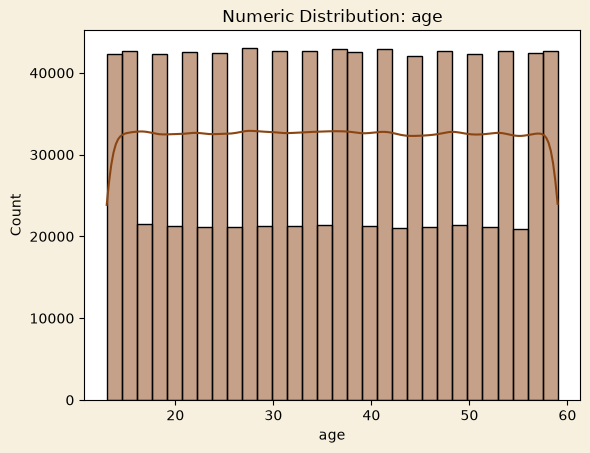

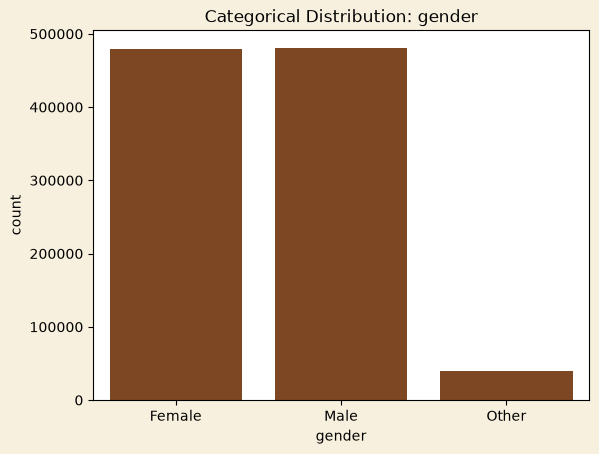

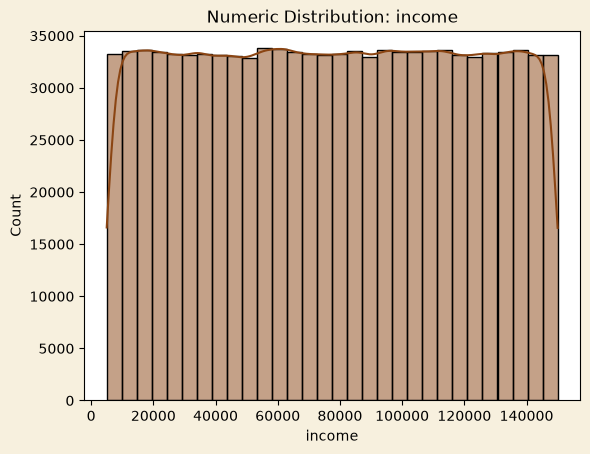

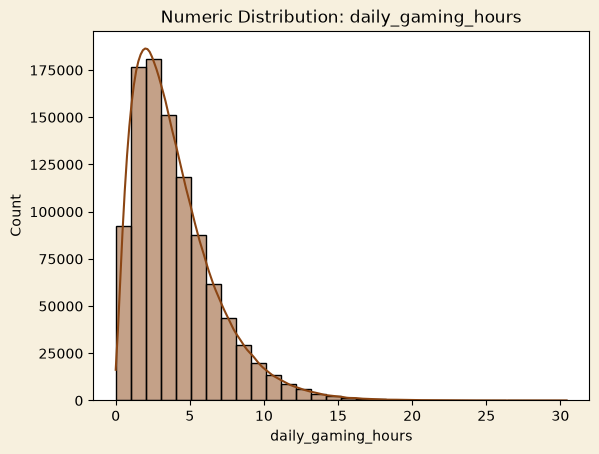

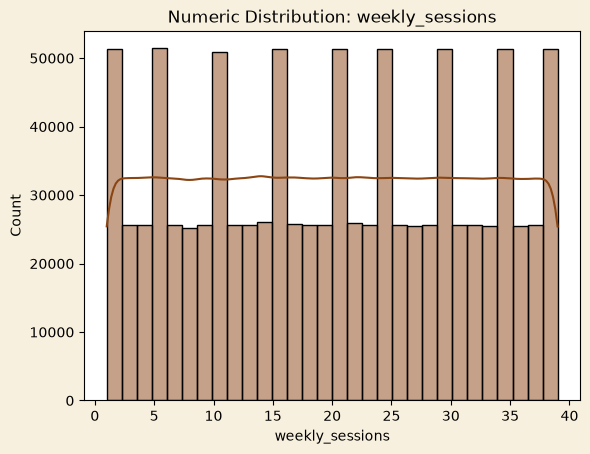

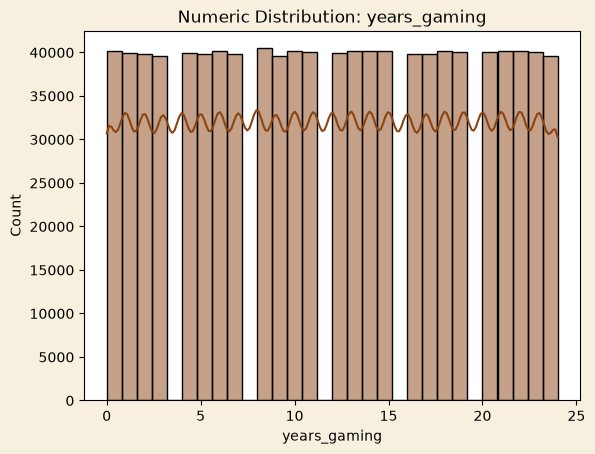

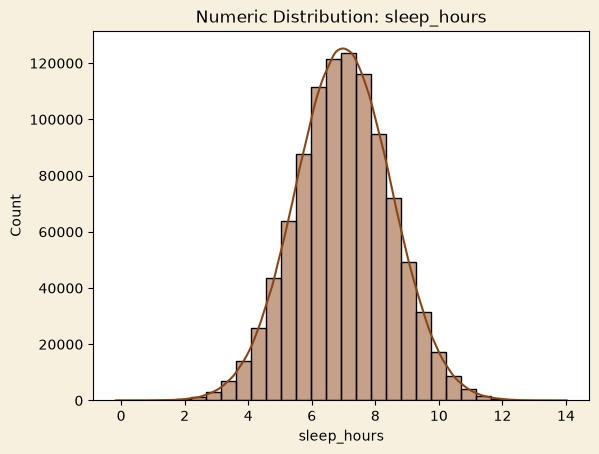

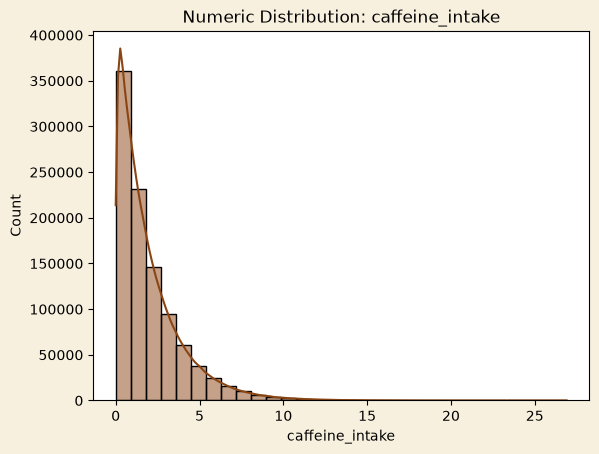

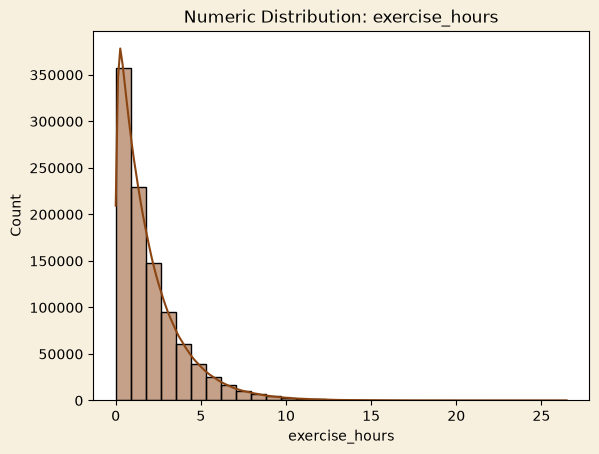

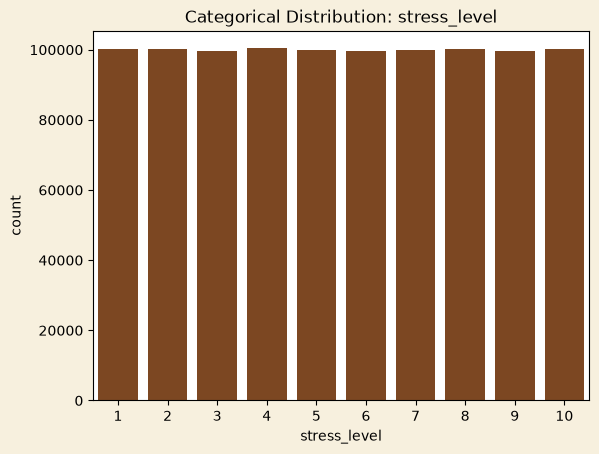

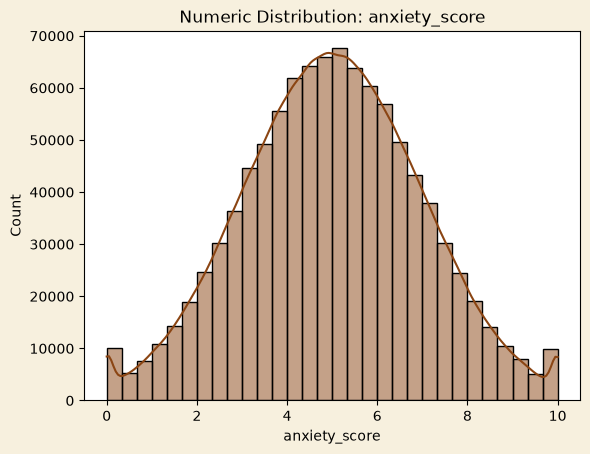

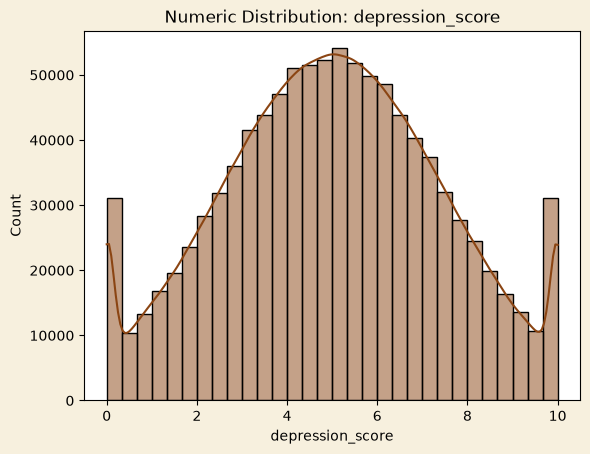

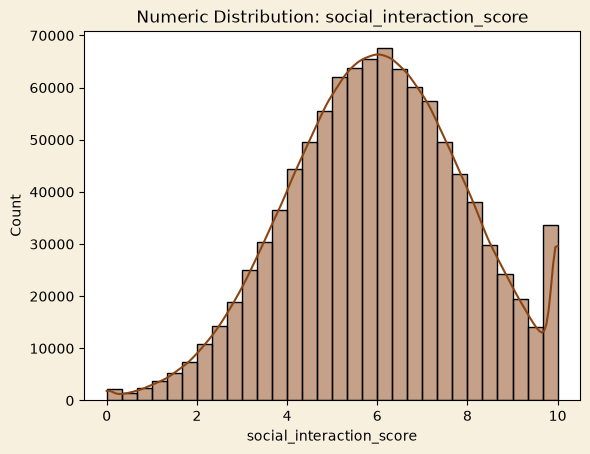

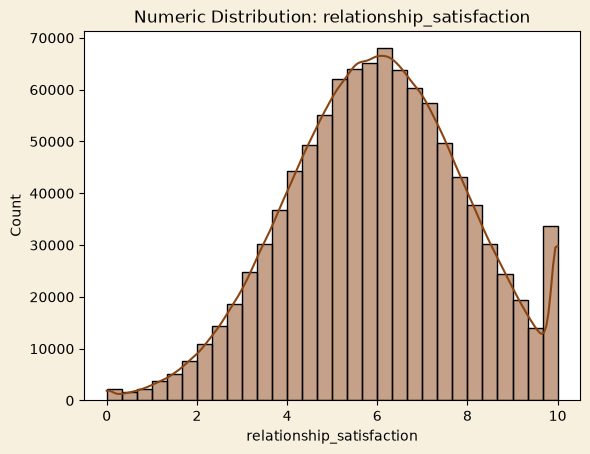

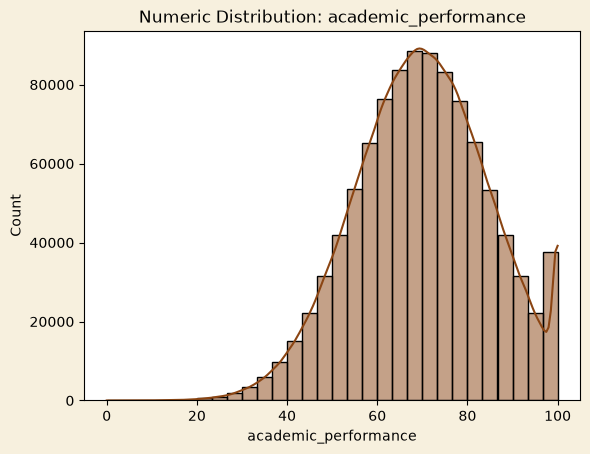

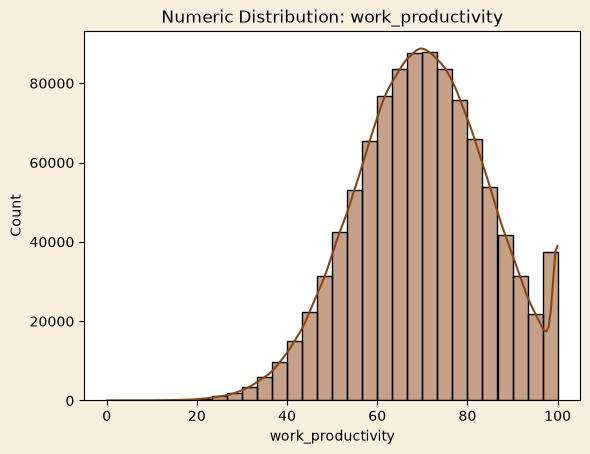

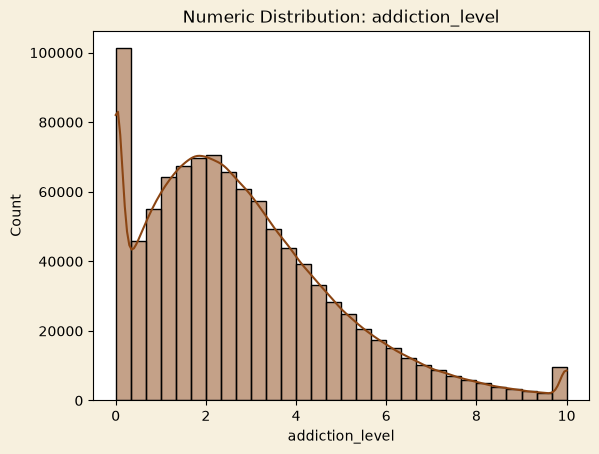

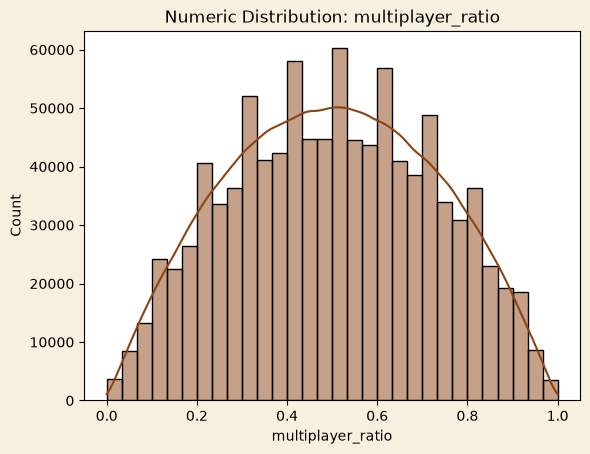

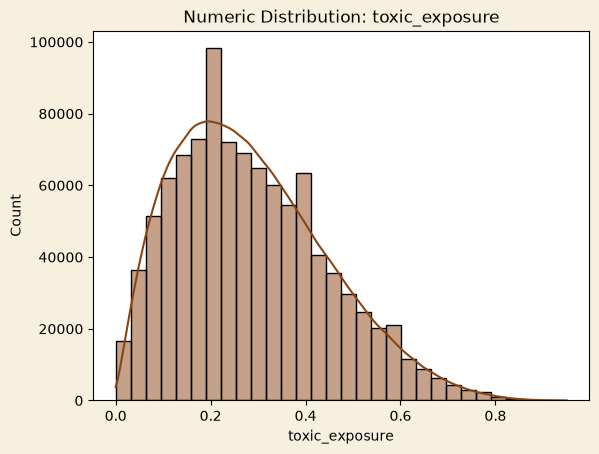

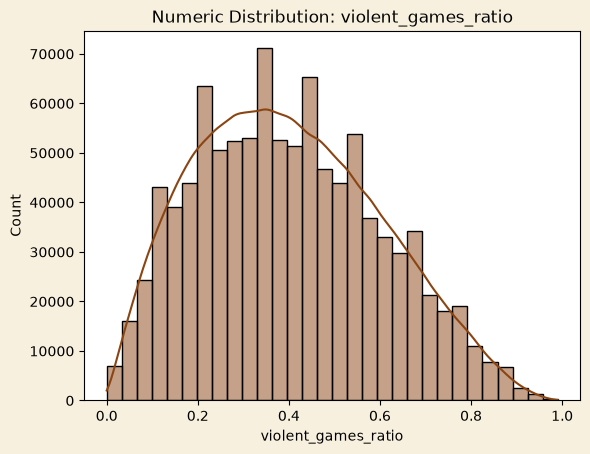

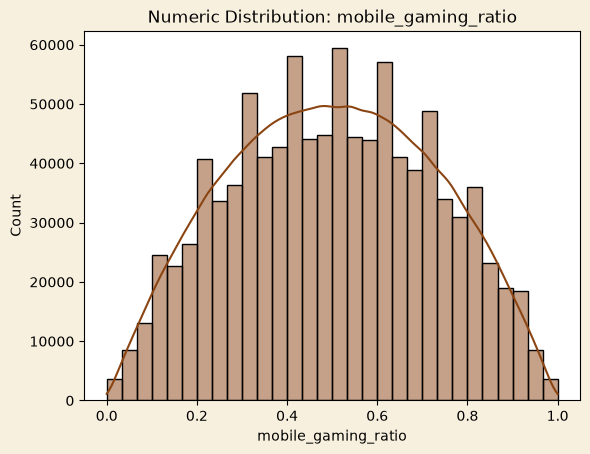

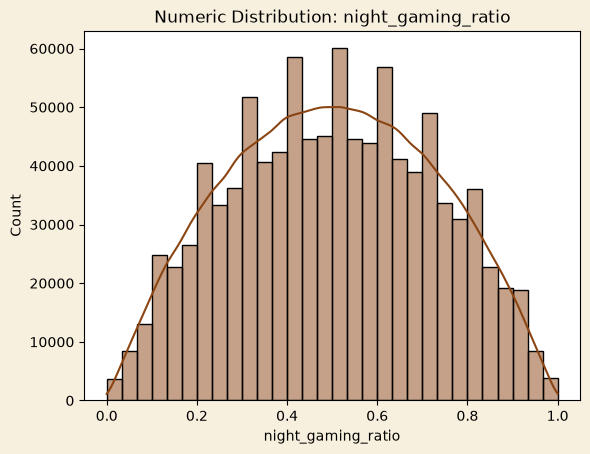

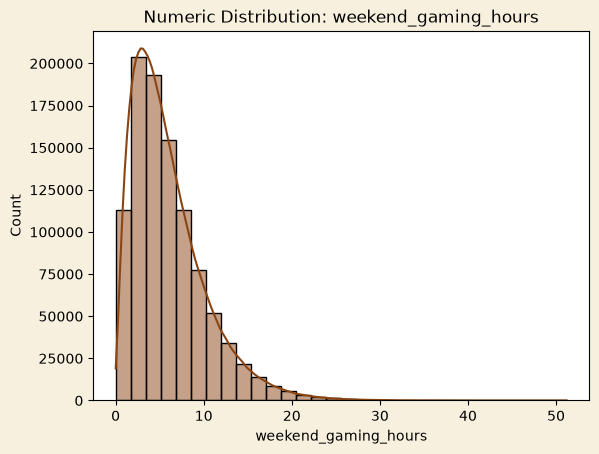

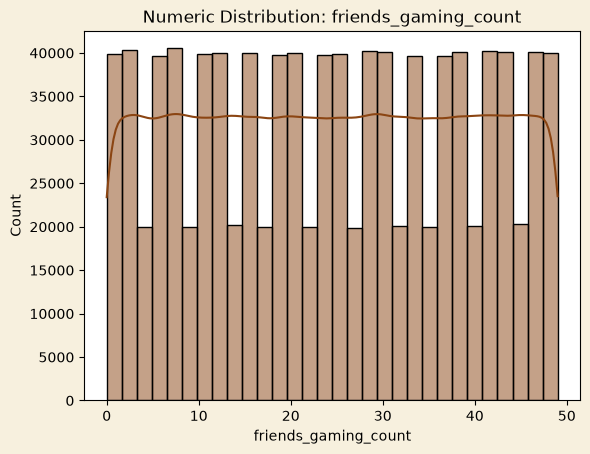

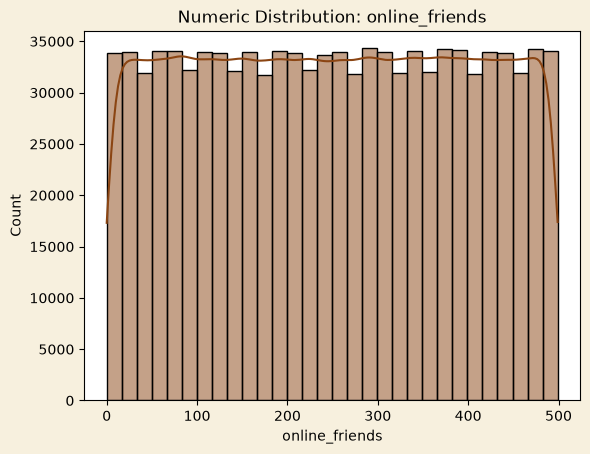

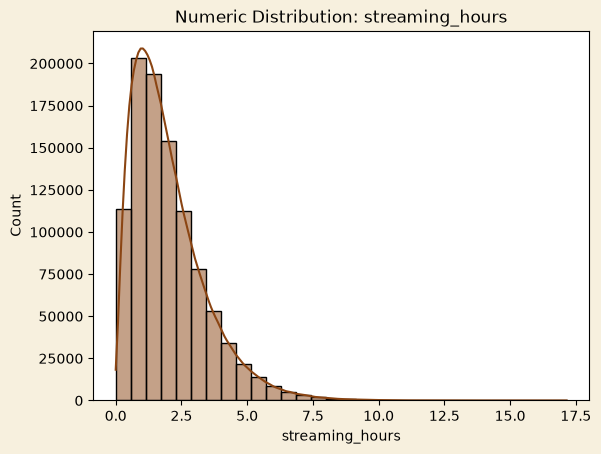

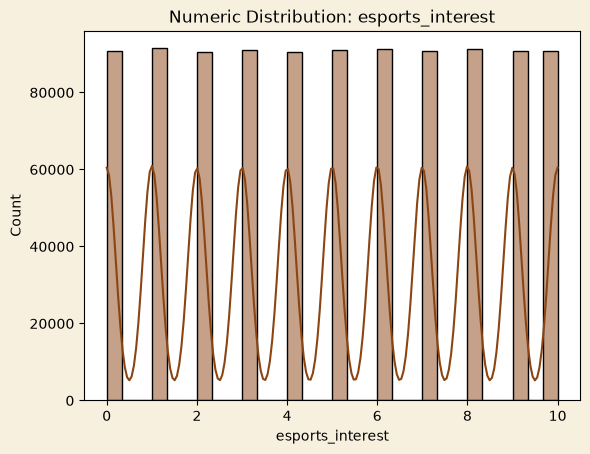

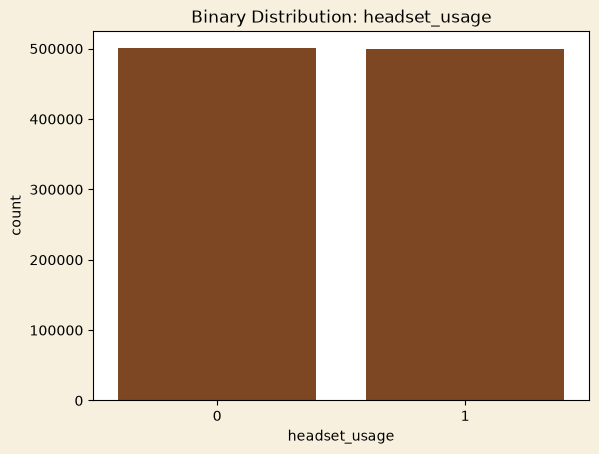

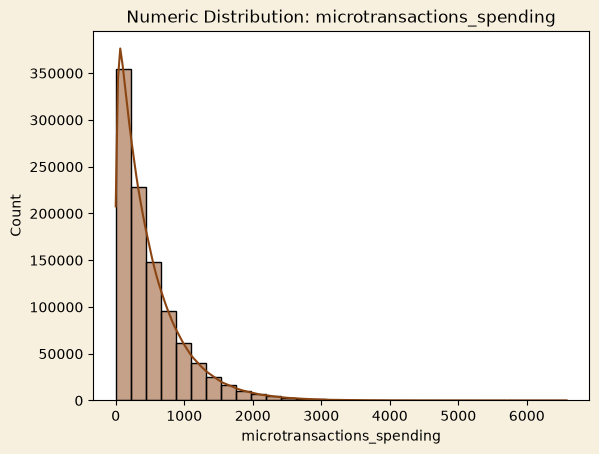

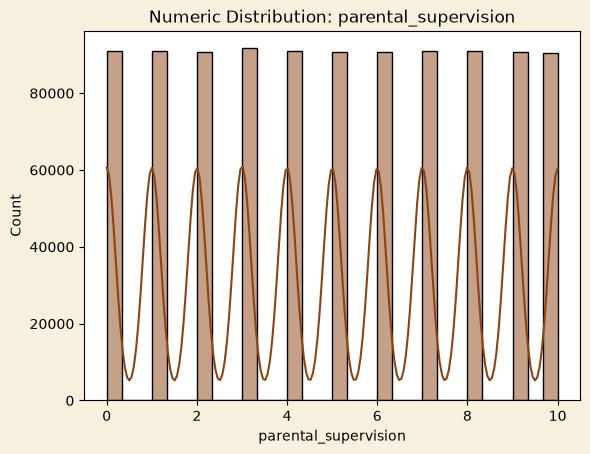

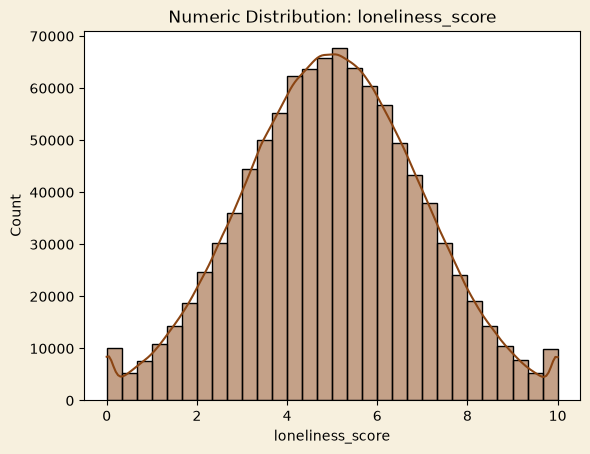

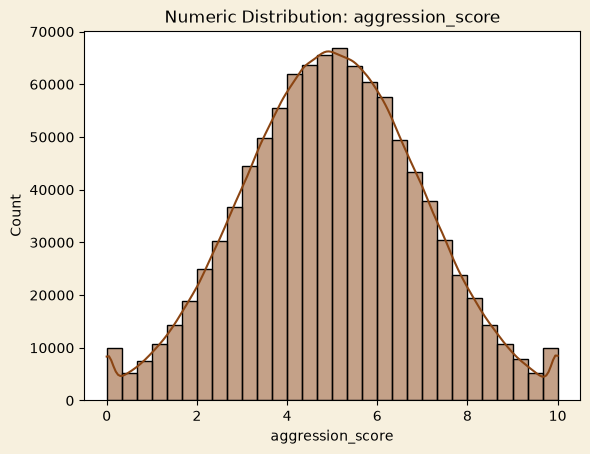

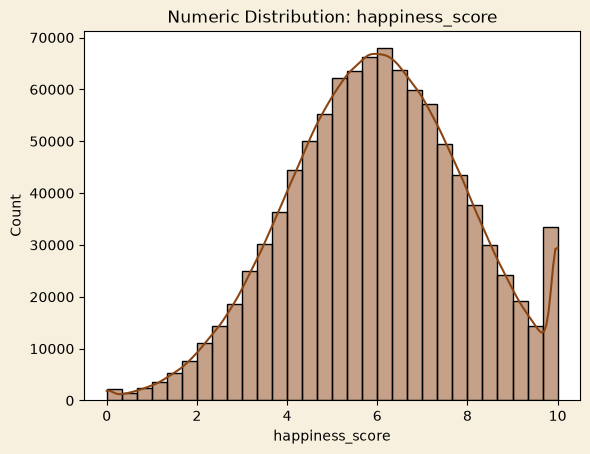

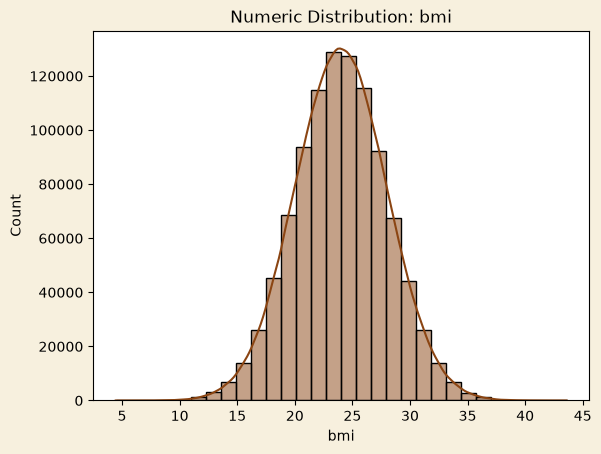

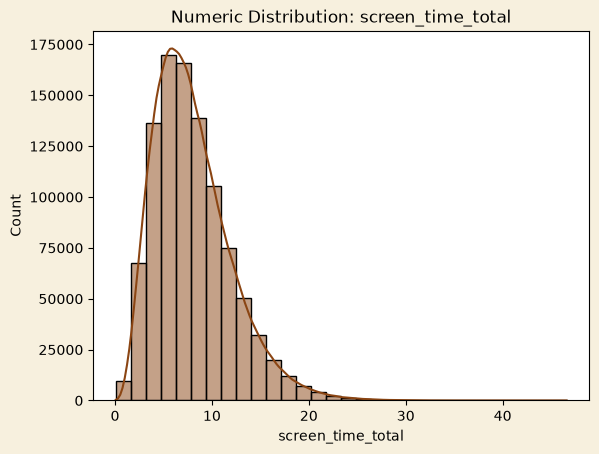

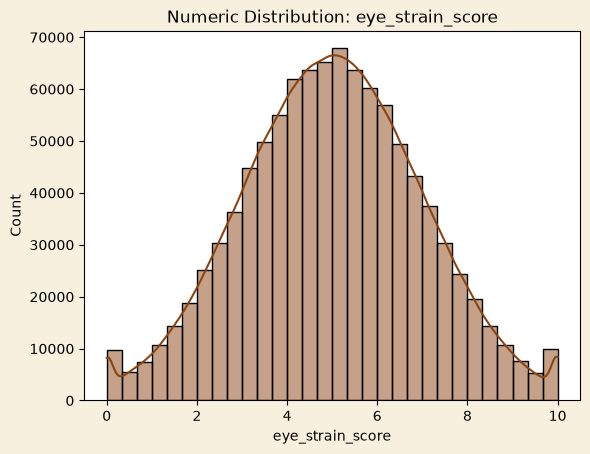

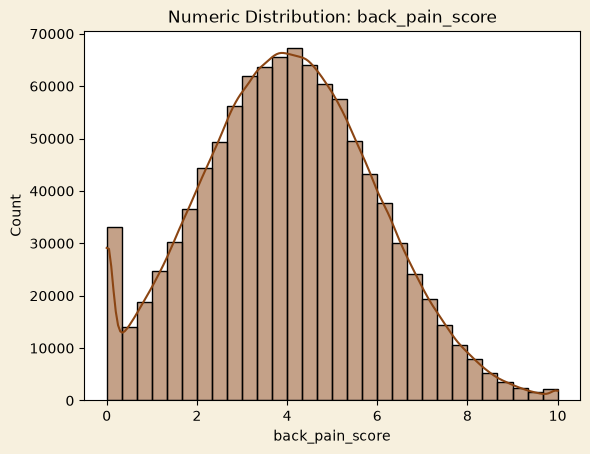

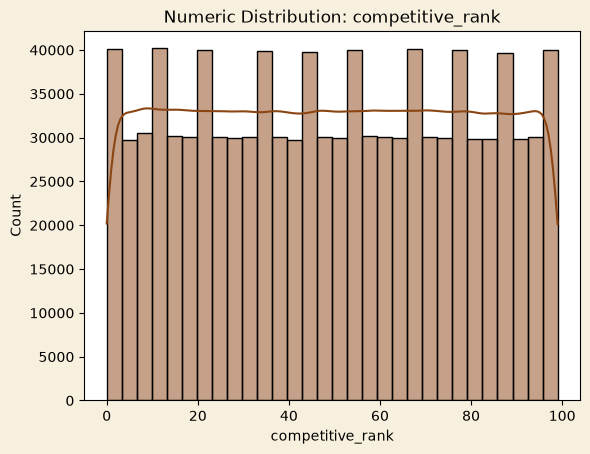

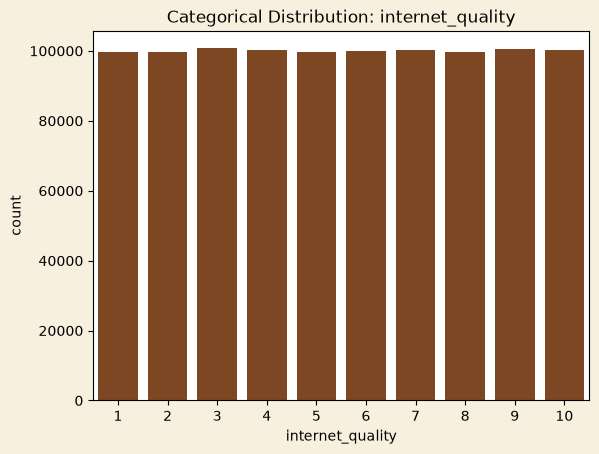

In [19]:
# Create distribution plots


for col in inf_data.columns:
    unique_vals = inf_data[col].nunique()
    dtype = inf_data[col].dtype
    filename = f"{col}dist.png"

    if not os.path.exists(filename):
        plt.figure()
        if unique_vals == 2:
            sns.countplot(x=col, data=inf_data, color='saddlebrown')
            plt.title(f'Binary Distribution: {col}')
        elif dtype == 'object' or unique_vals <= 10:
            sns.countplot(x=col, data=inf_data, color='saddlebrown')
            plt.title(f'Categorical Distribution: {col}')
        else:
            sns.histplot(inf_data[col], bins=30, kde=True, color='saddlebrown')
            plt.title(f'Numeric Distribution: {col}')
        plt.savefig(filename)
        plt.show()
    else:
        print(f"{filename} already exists, skipping.")


The graphs are a lot to unpack at first glance, but there are some key observations we can make:
- A number of the columns, such as `eye_strain_score` and `esports_interest` are scores between 1-10, while others such as `night_gaming_ratio` are ratios between 0-1.
- Some columns such as `interney_quality` appear to have very little variation in the distributions of values; a possible explanation may be the sheer volume of data causing smaller patterns in the data to be harder to pick up on.
- Most of the distributions are fairly balanced, and do not appear to have any outliers.

**Checking assumptions of causal inference:**


- **Exchangeability:** We have listed some of the confounders that affect our target X and Y variables. We will extract them from our data and adjust for them in the analysis where possible.
- **Overlap:** We will check that for each value or range of confounders, there is a spread of Y values. We will do this by plotting the confounders against our Y variable (`m_health`).
- **SUTVA (Stable Unit Treatment Value Assumption):** We will assume that each individual's outcome is only affected by their own treatment status, not by the treatment status of others. We will also assume that the treatment is applied in the same way for all individuals in the study.

**Note: The dataset used in this project was sourced from [Kaggle](https://www.kaggle.com/datasets/sharmajicoder/gaming-and-mental-health) and contains synthetic data - this is a limitation of the project.**

In [20]:
# Subset required columns
subset = [
    'age', 'income', 'daily_gaming_hours',
    'years_gaming', 'sleep_hours', 'caffeine_intake', 'exercise_hours',
    'stress_level', 'anxiety_score', 'depression_score',
    'social_interaction_score', 'relationship_satisfaction',
    'academic_performance', 'work_productivity', 'addiction_level',
    'multiplayer_ratio', 'toxic_exposure', 'violent_games_ratio',
    'mobile_gaming_ratio', 'night_gaming_ratio', 'weekend_gaming_hours',
    'friends_gaming_count', 'online_friends',
    'parental_supervision', 'loneliness_score', 'aggression_score',
    'happiness_score', 'bmi', 'eye_strain_score',
    'back_pain_score', 'internet_quality'
]
subset_df = inf_data[subset]

# Visualise features in the subset